Fitted model: y = 0.002984x^2 + -0.0289x + 67.43
RMSE: 1.37 ms
Predicted response at 450 users: 658.62 ms


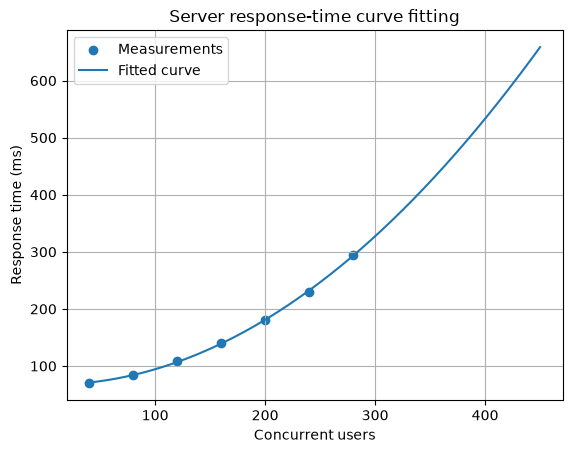

In [1]:
import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt

#M. Curve Fitting and Approximation

# Concurrent users and measured server response time (milliseconds)
users = np.array([40, 80, 120, 160, 200, 240, 280], dtype=float)
response_ms = np.array([70, 85, 108, 140, 180, 230, 295], dtype=float)

# A simple quadratic model for increasing delay
def model(x, a, b, c):
    return a*x**2 + b*x + c

parameters, covariance = curve_fit(model, users, response_ms)
a, b, c = parameters

predicted = model(users, a, b, c)
rmse = np.sqrt(np.mean((response_ms - predicted)**2))

print(f"Fitted model: y = {a:.6f}x^2 + {b:.4f}x + {c:.2f}")
print(f"RMSE: {rmse:.2f} ms")
print(f"Predicted response at 450 users: {model(450, a, b, c):.2f} ms")

x_plot = np.linspace(users.min(), 450, 300)
plt.scatter(users, response_ms, label="Measurements")
plt.plot(x_plot, model(x_plot, a, b, c), label="Fitted curve")
plt.xlabel("Concurrent users")
plt.ylabel("Response time (ms)")
plt.title("Server response-time curve fitting")
plt.legend()
plt.grid(True)
plt.show()